## 1. Import libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the data

In [6]:
path_train ="GiveMeSomeCredit.csv"

data= pd.read_csv(path_train)

print("shape", data.shape)
data.head(10)

shape (149724, 14)


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1
5,1,1.459344,54,F,3,3,1718.000000,NaN,18,9,0,7,0.0,2
6,1,14.540918,45,F,3,3,1.151865,3726.0,11,0,2,7,3.0,3
7,1,0.915053,48,M,2,1,0.652057,2600.0,8,0,1,7,0.0,3
8,1,1.000000,31,F,2,0,503.000000,NaN,4,7,0,7,0.0,2
9,0,1.445042,38,F,3,0,0.136132,4715.0,5,3,0,7,2.0,0


In [7]:
df=data.copy()

## 3. Understand the structure


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149724 entries, 0 to 149723
Data columns (total 14 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin                          149724 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  149724 non-null  float64
 2   age                                   149724 non-null  int64  
 3   SEX                                   149724 non-null  object 
 4   EDUCATION                             149724 non-null  int64  
 5   NumberOfTime30-59DaysPastDueNotWorse  149724 non-null  int64  
 6   DebtRatio                             149724 non-null  float64
 7   MonthlyIncome                         120117 non-null  float64
 8   NumberOfOpenCreditLinesAndLoans       149724 non-null  int64  
 9   NumberOfTimes90DaysLate               149724 non-null  int64  
 10  NumberRealEstateLoansOrLines          149724 non-null  int64  
 11  

In [9]:
df["SEX"] = df["SEX"].map({
    "M": 0,
    "F": 1
})

In [10]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 149724
Number of columns: 14


## 4. Define the target


In [11]:
target = "SeriousDlqin"

print("Target:", target)
print("Unique values:")
print(df[target].unique())

Target: SeriousDlqin
Unique values:
[1 0]


In [12]:
target_summary = pd.DataFrame({
    "Count": df[target].value_counts(),
    "Percent": df[target].value_counts(normalize=True).mul(100).round(2)
})

target_summary

,Count,Percent
SeriousDlqin,,
0,139845,93.4
1,9879,6.6


## 5. Duplicate rows

In [13]:
duplicate_count = df.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)


Number of duplicated rows: 142


In [14]:
df[df.duplicated(keep=False)]


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
30045,0,1.0,32,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30050,0,1.0,32,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30067,0,1.0,37,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30070,0,1.0,37,1,3,0,0.0,NaN,0,1,0,0,0.0,0
121347,0,1.0,22,1,1,0,0.0,929.0,1,0,0,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149706,0,0.0,42,0,3,0,0.0,NaN,2,0,0,0,0.0,0
149709,0,0.0,79,1,3,0,0.0,NaN,1,0,0,0,NaN,0
149714,0,0.0,23,1,2,0,0.0,NaN,2,0,0,0,0.0,0
149717,0,0.0,59,1,1,0,0.0,NaN,1,0,0,0,0.0,0


## 6. Linear Correlation

In [15]:
corr = df.corr()

corr[target].sort_values(ascending=False)

SeriousDlqin                            1.000000
NumberOfDefault                         0.921535
NumberOfTimes90DaysLate                 0.314557
NumberOfTime30-59DaysPastDueNotWorse    0.274554
NumberOfTime60-89DaysPastDueNotWorse    0.268128
NumberOfDependents                      0.047442
EDUCATION                               0.002214
RevolvingUtilizationOfUnsecuredLines   -0.001625
SEX                                    -0.002724
NumberRealEstateLoansOrLines           -0.003895
DebtRatio                              -0.008778
MonthlyIncome                          -0.023343
NumberOfOpenCreditLinesAndLoans        -0.024219
age                                    -0.112966
Name: SeriousDlqin, dtype: float64

## 7. Target Leakage

In [16]:
print(df[["NumberOfDefault", target]].head(20))


    NumberOfDefault  SeriousDlqin
0                 1             1
1                 0             0
2                 0             0
3                 2             1
4                 1             1
5                 2             1
6                 3             1
7                 3             1
8                 2             1
9                 0             0
10                0             0
11                0             0
12                0             0
13                0             0
14                3             1
15                1             1
16                2             1
17                0             0
18                2             1
19                2             1


In [17]:
df = df.drop(columns=["NumberOfDefault"])

print("Leaked feature removed.")

Leaked feature removed.


## 8. Data validation: impossible value


In [18]:
print("Age < 18:", (df["age"] < 18).sum())
print("Age > 100:", (df["age"] > 100).sum())
print("MonthlyIncome < 0:", (df["MonthlyIncome"] < 0).sum())
print("NumberOfTimes90DaysLate < 0:", (df["NumberOfTimes90DaysLate"] < 0).sum())
print("NumberRealEstateLoansOrLines < 0:", (df["NumberRealEstateLoansOrLines"] < 0).sum())

Age < 18: 1
Age > 100: 13
MonthlyIncome < 0: 0
NumberOfTimes90DaysLate < 0: 0
NumberRealEstateLoansOrLines < 0: 0


In [19]:
df = df[(df["age"] >= 18) & (df["age"] <= 100)]

## 9. Train-Test Split

In [20]:
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (104797, 12)
X_test : (44913, 12)
y_train: (104797,)
y_test : (44913,)


In [21]:
print("Overall:")
print(y.value_counts(normalize=True).mul(100).round(2))

print("\nTrain:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Overall:
SeriousDlqin
0    93.4
1     6.6
Name: proportion, dtype: float64

Train:
SeriousDlqin
0    93.4
1     6.6
Name: proportion, dtype: float64

Test:
SeriousDlqin
0    93.4
1     6.6
Name: proportion, dtype: float64


In [22]:
train_df = X_train.copy()
train_df[target] = y_train

print("Train dataframe shape:", train_df.shape)
train_df.head()

Train dataframe shape: (104797, 13)


,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin
134668,0.203223,60,1,2,0,1600.000000,NaN,8,0,1,0,0.0,0
119703,1.000000,24,0,3,0,0.100074,1358.0,3,0,0,0,0.0,0
37115,0.200152,49,0,1,0,0.224416,12917.0,8,0,1,0,0.0,0
141624,0.025735,78,1,1,0,347.000000,NaN,7,0,0,0,0.0,0
139483,0.133169,29,0,3,0,723.000000,NaN,5,0,0,0,0.0,0


In [23]:
test_df = X_test.copy()
test_df[target] = y_test

print("Train dataframe shape:", test_df.shape)
test_df.head()

Train dataframe shape: (44913, 13)


,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin
76820,0.021663,61,1,3,0,0.500453,5516.0,8,0,2,0,0.0,0
135401,0.000000,62,1,3,0,1461.000000,NaN,14,0,1,0,0.0,0
5324,0.060561,39,1,3,0,0.198144,12500.0,8,0,1,1,2.0,0
90486,0.824374,30,0,2,0,0.100439,4330.0,4,0,0,0,0.0,0
43461,1.000000,41,1,1,0,0.023712,10500.0,1,0,1,0,2.0,1


## 10. Missing value

In [24]:
missing_train = pd.DataFrame({
    "Missing_Count": train_df.isnull().sum(),
    "Missing_Percent": (
        train_df.isnull().mean().mul(100).round(2)
    )
})

missing_train = missing_train.sort_values(
    "Missing_Percent",
    ascending=False
)

missing_train

,Missing_Count,Missing_Percent
MonthlyIncome,20723,19.77
NumberOfDependents,2767,2.64
SEX,0,0.00
age,0,0.00
RevolvingUtilizationOfUnsecuredLines,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
EDUCATION,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00
DebtRatio,0,0.00
NumberOfTimes90DaysLate,0,0.00


In [25]:
train_df.groupby(
    train_df["MonthlyIncome"].isna()
)["SeriousDlqin"].mean()

MonthlyIncome
False    0.068761
True     0.054722
Name: SeriousDlqin, dtype: float64

In [26]:
train_df.groupby(
    train_df["NumberOfDependents"].isna()
)["SeriousDlqin"].mean()

NumberOfDependents
False    0.066627
True     0.042284
Name: SeriousDlqin, dtype: float64

In [27]:
# Missing values in Test
missing_test = pd.DataFrame({
    "Missing_Count": test_df.isnull().sum(),
    "Missing_Percent": test_df.isnull().mean().mul(100).round(2)
})

missing_test = missing_test.sort_values(
    "Missing_Percent",
    ascending=False
)

missing_test

,Missing_Count,Missing_Percent
MonthlyIncome,8877,19.76
NumberOfDependents,1123,2.50
SEX,0,0.00
age,0,0.00
RevolvingUtilizationOfUnsecuredLines,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
EDUCATION,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00
DebtRatio,0,0.00
NumberOfTimes90DaysLate,0,0.00


In [28]:
# Train
train_df["MonthlyIncome_missing"] = (
    train_df["MonthlyIncome"].isna().astype(int)
)

# Test
test_df["MonthlyIncome_missing"] = (
    test_df["MonthlyIncome"].isna().astype(int)
)

In [29]:
income_median = train_df["MonthlyIncome"].median()

train_df["MonthlyIncome"] = train_df["MonthlyIncome"].fillna(
    income_median
)

test_df["MonthlyIncome"] = test_df["MonthlyIncome"].fillna(
    income_median
)

In [30]:
dependents_median = train_df["NumberOfDependents"].median()

train_df["NumberOfDependents"] = train_df[
    "NumberOfDependents"
].fillna(dependents_median)

test_df["NumberOfDependents"] = test_df[
    "NumberOfDependents"
].fillna(dependents_median)

 ## 11. Outlier analysis

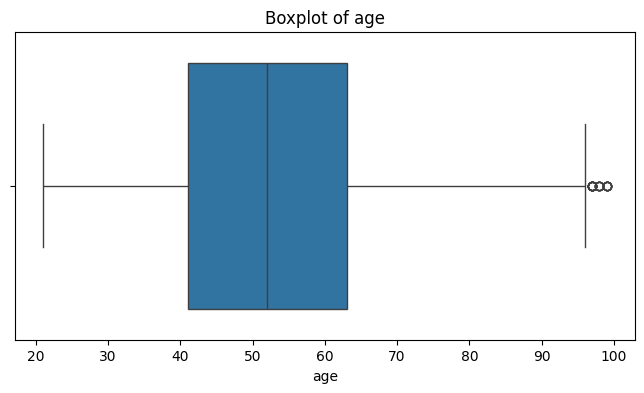

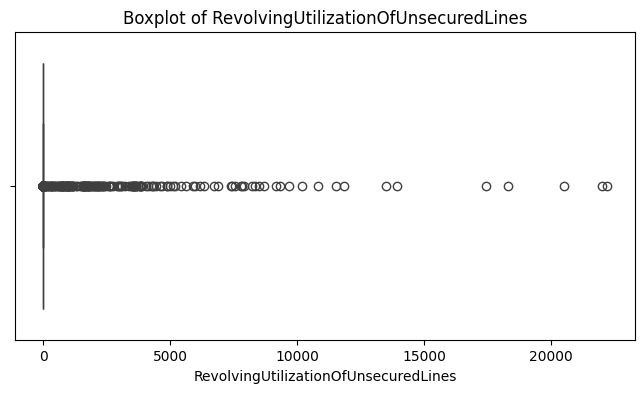

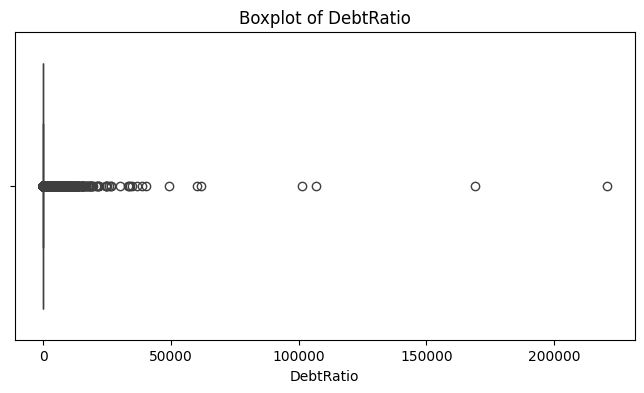

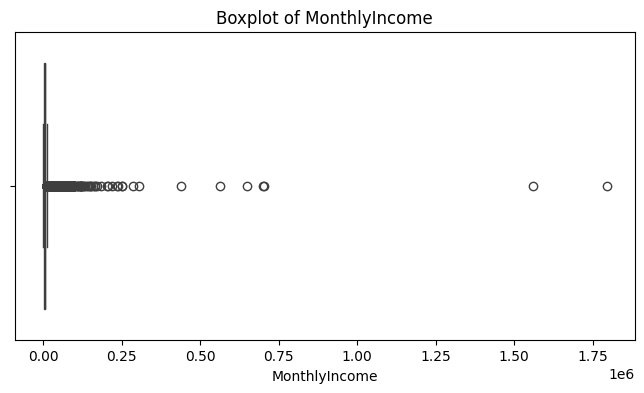

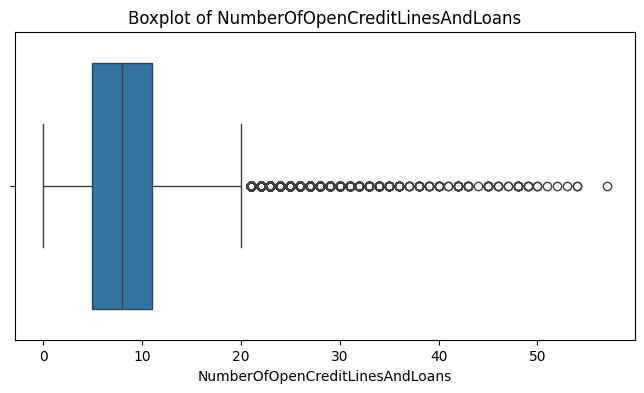

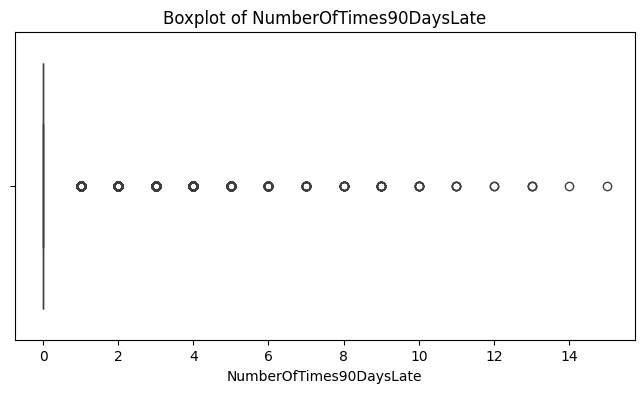

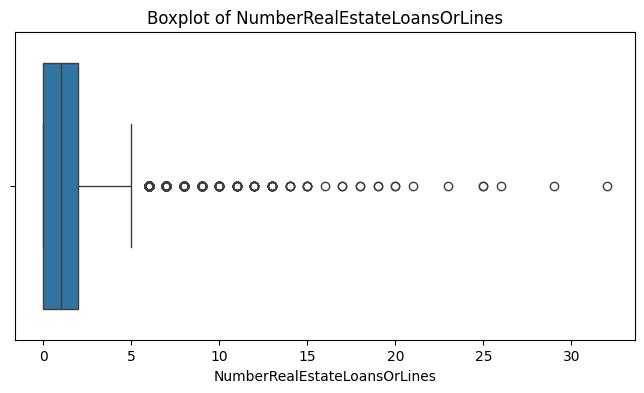

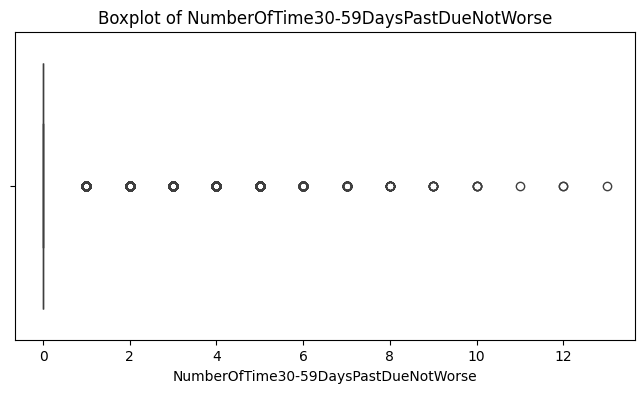

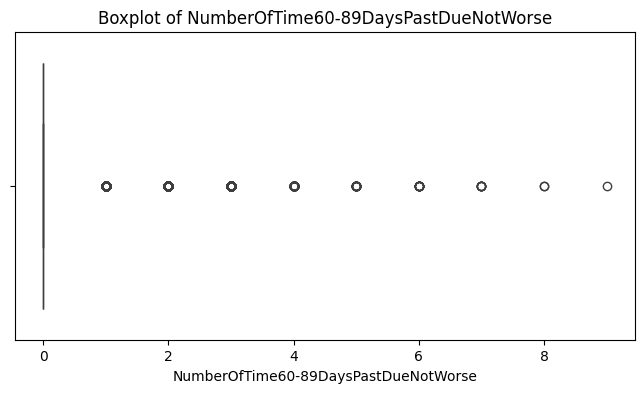

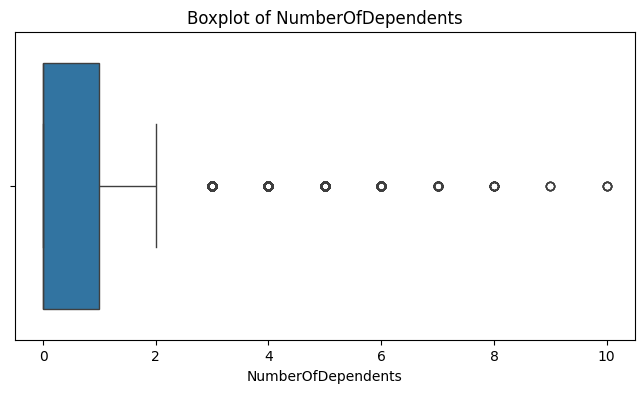

In [31]:
numeric_columns = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

for col in numeric_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=train_df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [32]:
numeric_cols = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

train_df["Is_Outlier"] = False

outlier_report = []

for col in numeric_cols:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    col_outlier = (
        (train_df[col] < lower) |
        (train_df[col] > upper)
    )

    train_df["Is_Outlier"] = (
        train_df["Is_Outlier"] |
        col_outlier
    )

    count = ((train_df[col] < lower) | (train_df[col] > upper)).sum()

    outlier_report.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Candidate_Outliers": count,
        "Outlier_Percent": round(count / len(train_df) * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_report)
outlier_report.sort_values("Outlier_Percent", ascending=False)

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Candidate_Outliers,Outlier_Percent
2,DebtRatio,0.175977,0.864820,0.688843,-0.857287,1.898084,21865,20.86
7,NumberOfTime30-59DaysPastDueNotWorse,0.000000,0.000000,0.000000,0.000000,0.000000,16510,15.75
9,NumberOfDependents,0.000000,1.000000,1.000000,-1.500000,2.500000,9337,8.91
3,MonthlyIncome,3923.000000,7420.000000,3497.000000,-1322.500000,12665.500000,6367,6.08
5,NumberOfTimes90DaysLate,0.000000,0.000000,0.000000,0.000000,0.000000,5652,5.39
8,NumberOfTime60-89DaysPastDueNotWorse,0.000000,0.000000,0.000000,0.000000,0.000000,5134,4.90
4,NumberOfOpenCreditLinesAndLoans,5.000000,11.000000,6.000000,-4.000000,20.000000,2752,2.63
1,RevolvingUtilizationOfUnsecuredLines,0.029924,0.555344,0.525421,-0.758207,1.343475,542,0.52
6,NumberRealEstateLoansOrLines,0.000000,2.000000,2.000000,-3.000000,5.000000,543,0.52
0,age,41.000000,63.000000,22.000000,8.000000,96.000000,21,0.02


In [33]:
outlier_distribution = (
    train_df[train_df["Is_Outlier"]]["SeriousDlqin"]
    .value_counts()
    .sort_index()
)

print(outlier_distribution)

SeriousDlqin
0    45783
1     5424
Name: count, dtype: int64


## 12. Univariate relationship with target


In [34]:
features_to_compare = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

train_df.groupby(target)[features_to_compare].mean().T

SeriousDlqin,0,1
age,52.785190,46.061171
RevolvingUtilizationOfUnsecuredLines,6.185745,6.001989
DebtRatio,352.223284,305.816230
MonthlyIncome,6447.125958,5644.865076
NumberOfOpenCreditLinesAndLoans,8.502452,7.946638
NumberOfTimes90DaysLate,0.049723,0.672451
NumberRealEstateLoansOrLines,1.021179,0.993926
NumberOfTime30-59DaysPastDueNotWorse,0.192936,0.977440
NumberOfTime60-89DaysPastDueNotWorse,0.041192,0.402025
NumberOfDependents,0.724372,0.941287


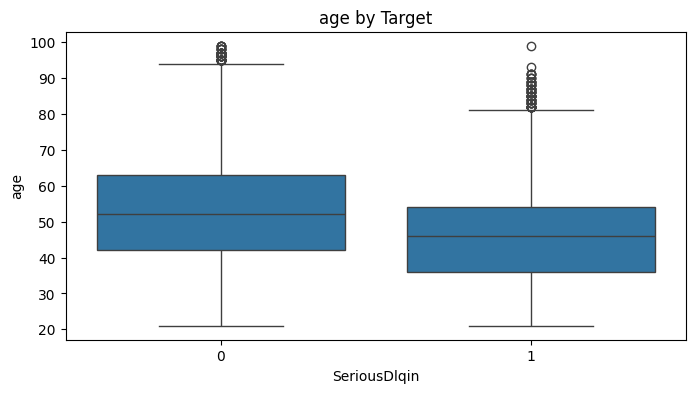

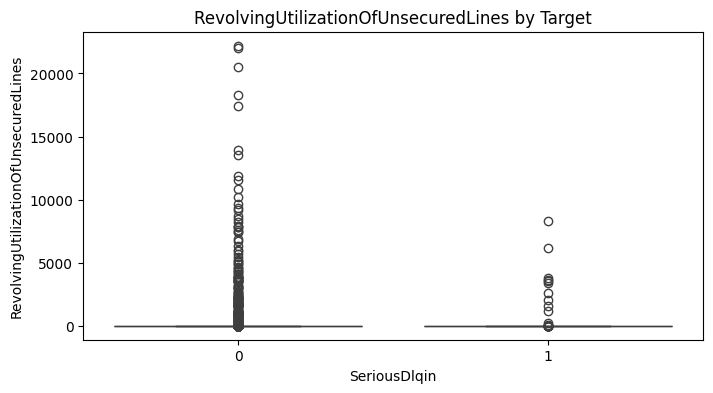

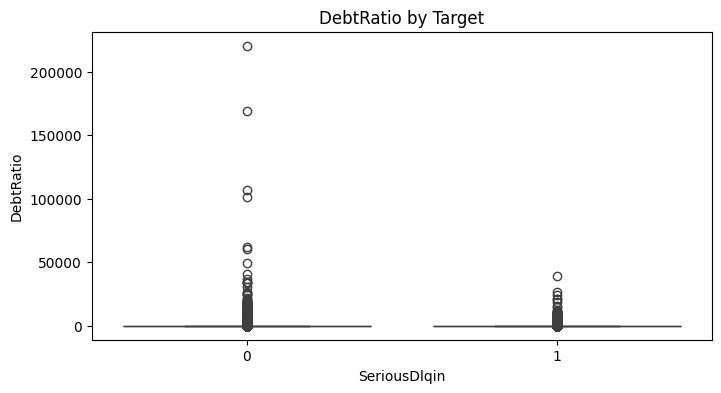

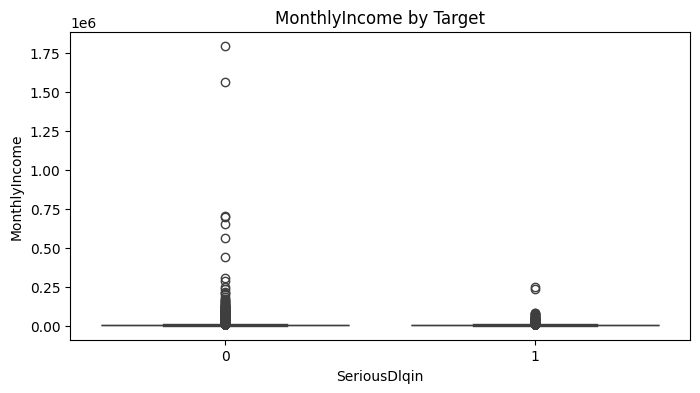

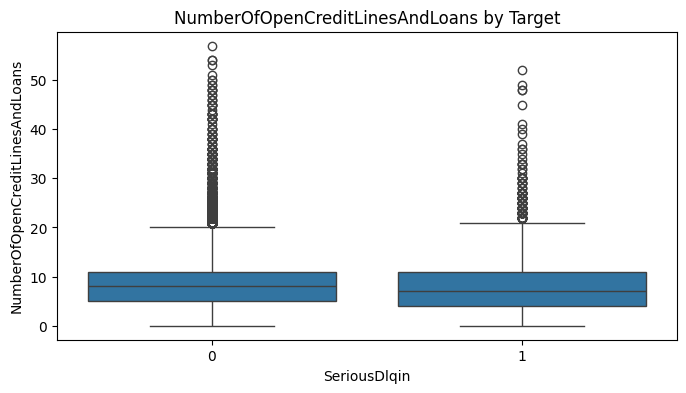

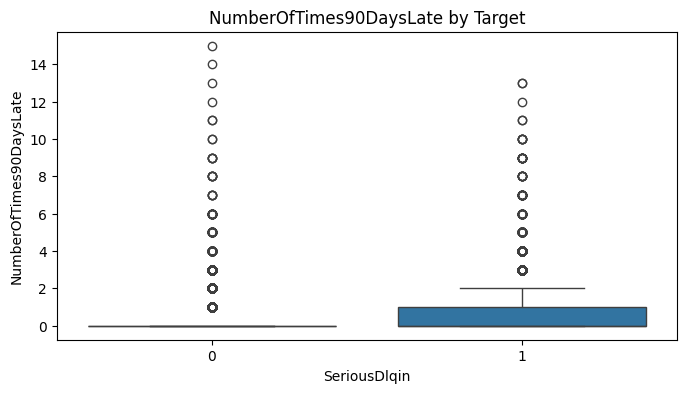

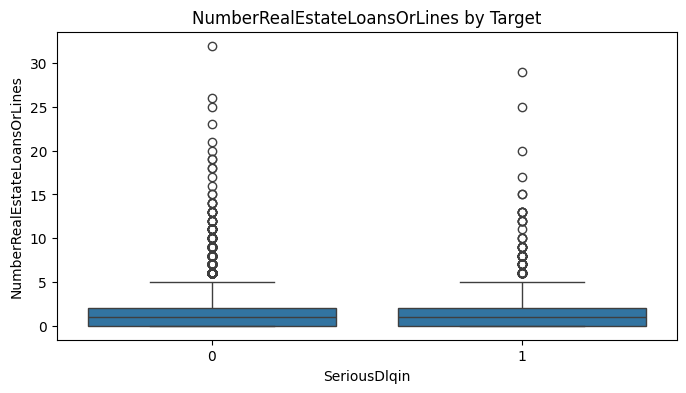

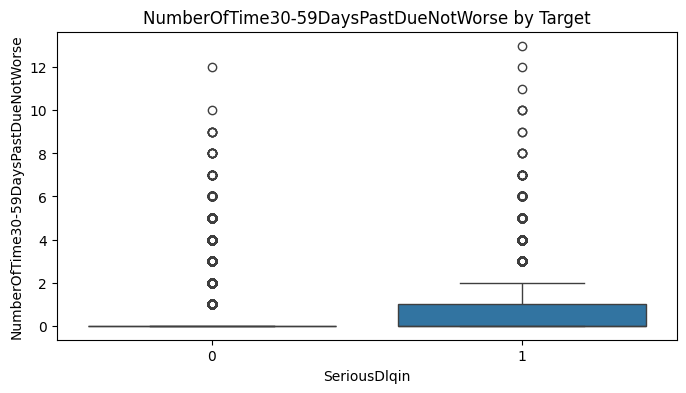

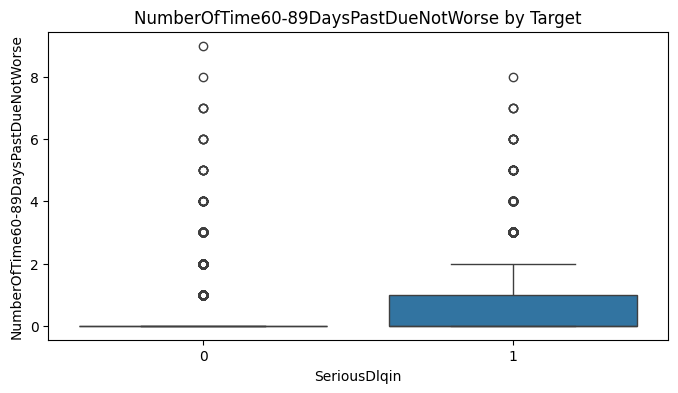

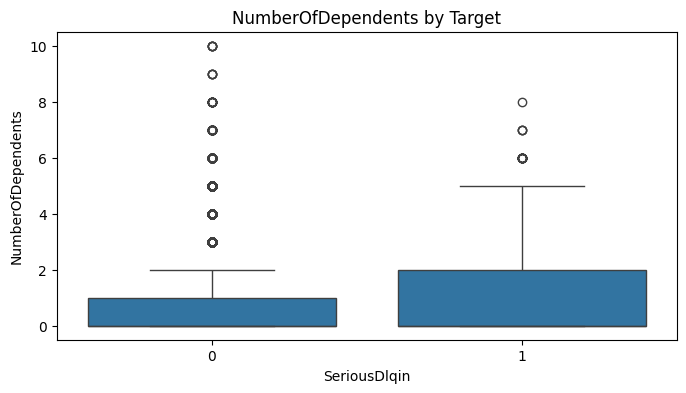

In [35]:
numeric_cols = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=train_df, x=target, y=col)
    plt.title(f"{col} by Target")
    plt.show()

## 13. Categorical analysis

In [36]:
# Check the new categorical features
print(train_df["SEX"].value_counts().sort_index())
print()
print(train_df["EDUCATION"].value_counts().sort_index())

SEX
0    41808
1    62989
Name: count, dtype: int64

EDUCATION
1    26275
2    36528
3    36724
4     5270
Name: count, dtype: int64


In [37]:
sex_risk = train_df.groupby("SEX")[target].agg(
    Customers="size",
    Bad_Rate="mean"
)
sex_risk["Bad_Rate"] *= 100
sex_risk

,Customers,Bad_Rate
SEX,,
0,41808,6.580080
1,62989,6.610678


In [38]:
education_risk = df.groupby("EDUCATION")[target].agg(
    Customers="size",
    Bad_Rate="mean"
)
education_risk["Bad_Rate"] *= 100
education_risk

,Customers,Bad_Rate
EDUCATION,,
1,37561,6.440191
2,52178,6.713557
3,52482,6.569872
4,7489,6.783282


## 14. Feature Engineering

In [39]:
train_df["TotalPastDue"] = (
    train_df["NumberOfTime30-59DaysPastDueNotWorse"]
    + train_df["NumberOfTime60-89DaysPastDueNotWorse"]
    + train_df["NumberOfTimes90DaysLate"]
)

train_df[[
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "TotalPastDue"
]].head()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,TotalPastDue
134668,0,0,0,0
119703,0,0,0,0
37115,0,0,0,0
141624,0,0,0,0
139483,0,0,0,0


In [40]:
test_df["TotalPastDue"] = (
    test_df["NumberOfTime30-59DaysPastDueNotWorse"]
    + test_df["NumberOfTime60-89DaysPastDueNotWorse"]
    + test_df["NumberOfTimes90DaysLate"]
)

test_df[[
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "TotalPastDue"
]].head()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,TotalPastDue
76820,0,0,0,0
135401,0,0,0,0
5324,0,1,0,1
90486,0,0,0,0
43461,0,0,0,0


In [41]:
train_df["Has90DaysLate"] = (train_df["NumberOfTimes90DaysLate"] > 0).astype(int)

train_df["Has90DaysLate"].value_counts()

Has90DaysLate
0    99145
1     5652
Name: count, dtype: int64

In [42]:
test_df["Has90DaysLate"] = (test_df["NumberOfTimes90DaysLate"] > 0).astype(int)

test_df["Has90DaysLate"].value_counts()

Has90DaysLate
0    42497
1     2416
Name: count, dtype: int64

In [43]:
pd.crosstab(
    train_df["Has90DaysLate"],
    train_df[target],
    normalize="index"
).round(3)

SeriousDlqin,0,1
Has90DaysLate,,
0,0.954,0.046
1,0.581,0.419


In [44]:
def get_worst_delay_status(row):
    if row["NumberOfTimes90DaysLate"] > 0:
        return 3
    elif row["NumberOfTime60-89DaysPastDueNotWorse"] > 0:
        return 2
    elif row["NumberOfTime30-59DaysPastDueNotWorse"] > 0:
        return 1
    else:
        return 0


train_df["WorstDelayStatus"] = train_df.apply(get_worst_delay_status, axis=1)
test_df["WorstDelayStatus"] = test_df.apply(get_worst_delay_status, axis=1)

## 15. Binning

In [45]:
bins = [0, 29, 39, 49, 59, 69, np.inf]
labels = ["<30", "30-39", "40-49", "50-59", "60-69", "70+"]

train_df["AgeGroup"] = pd.cut(
    train_df["age"],
    bins=bins,
    labels=labels
)

train_df["AgeGroup"].value_counts().sort_index()

AgeGroup
<30       6103
30-39    16157
40-49    23946
50-59    24736
60-69    20305
70+      13550
Name: count, dtype: int64

In [46]:
_, bins = pd.qcut(
    train_df["DebtRatio"],
    q=5,
    retbins=True,
    duplicates="drop"
)

train_df["DebtRatioGroup"] = pd.cut(
    train_df["DebtRatio"],
    bins=bins
)

## 16. WOE and Information Value


In [47]:
woe_table = train_df.groupby(
    "AgeGroup",
    observed=False
)[target].agg(
    Total="size",
    Bad="sum"
)

woe_table["Good"] = woe_table["Total"] - woe_table["Bad"]

woe_table

,Total,Bad,Good
AgeGroup,,,
<30,6103,682,5421
30-39,16157,1610,14547
40-49,23946,1992,21954
50-59,24736,1592,23144
60-69,20305,723,19582
70+,13550,316,13234


In [48]:
woe_table["Bad_Dist"] = (
    woe_table["Bad"] / woe_table["Bad"].sum()
)

woe_table["Good_Dist"] = (
    woe_table["Good"] / woe_table["Good"].sum()
)

In [49]:
woe_table["WOE"] = np.log(
    woe_table["Good_Dist"] /
    woe_table["Bad_Dist"]
)

woe_table["IV"] = (
    woe_table["Good_Dist"] -
    woe_table["Bad_Dist"]
) * woe_table["WOE"]

In [50]:
IV = woe_table["IV"].sum()

print("IV =", IV)

IV = 0.2379444781393713


In [51]:
train_df.drop(
    columns=["AgeGroup", "DebtRatioGroup"],
    inplace=True
)

## 17. Feature Redundancy

In [52]:
numeric_columns = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",

    # New Features
    "TotalPastDue",
    "Has90DaysLate",
    "WorstDelayStatus",
    "MonthlyIncome_missing"
]

X = train_df[numeric_columns].copy()

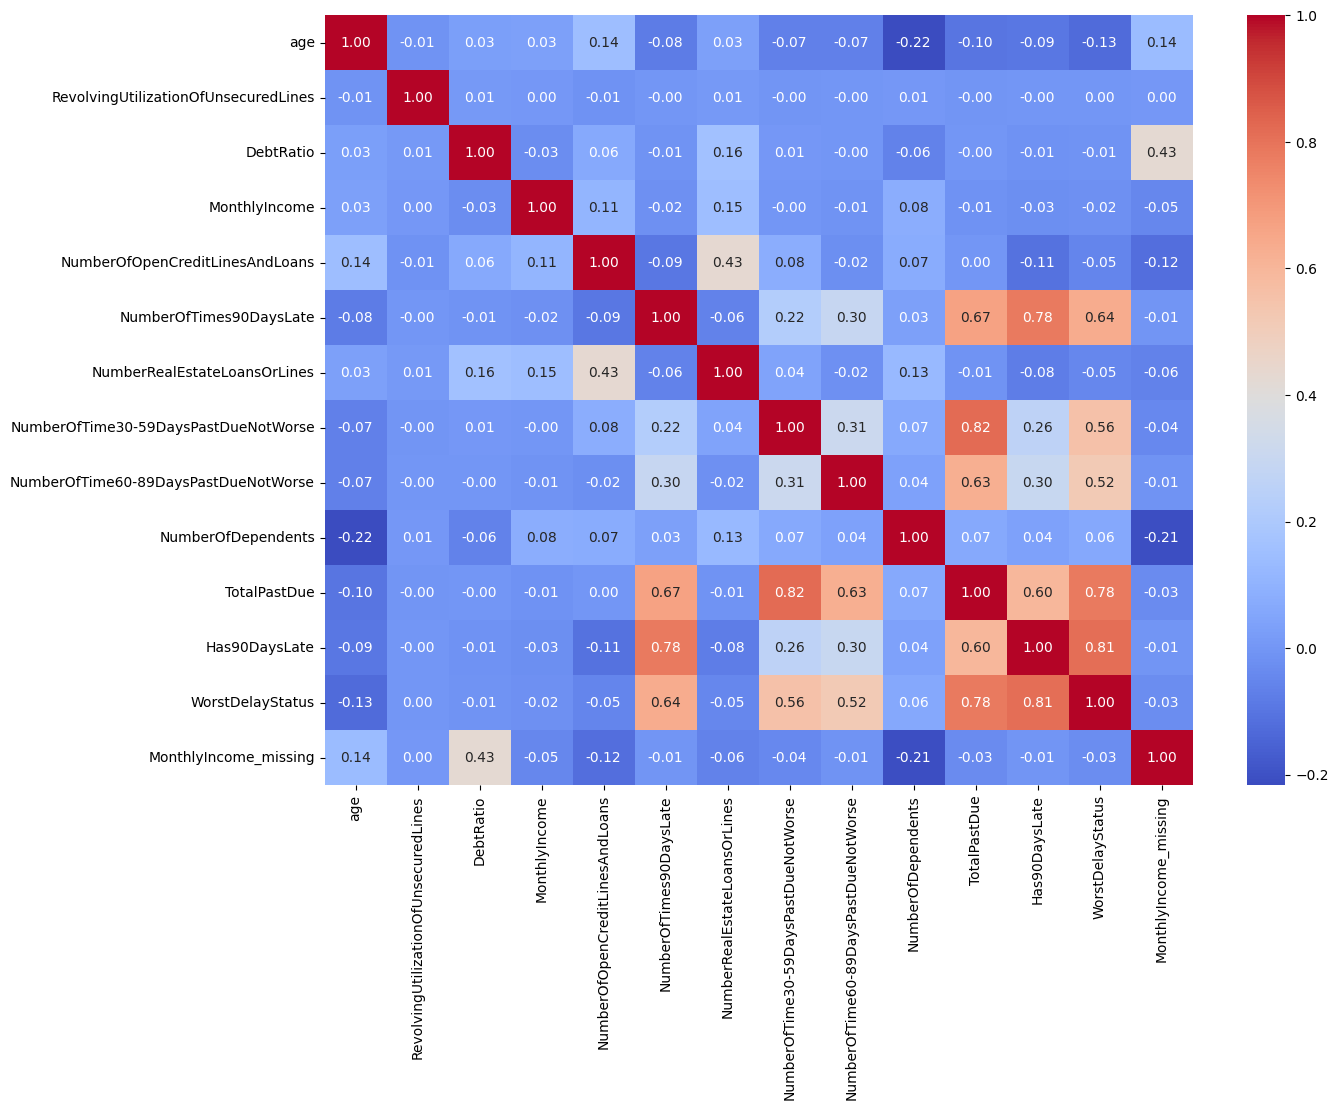

In [53]:
corr_matrix = X.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

## 18. Mutual information

TotalPastDue                            0.048711
WorstDelayStatus                        0.047974
RevolvingUtilizationOfUnsecuredLines    0.036869
NumberOfTimes90DaysLate                 0.032128
Has90DaysLate                           0.031938
NumberOfTime30-59DaysPastDueNotWorse    0.026587
NumberOfTime60-89DaysPastDueNotWorse    0.019390
SEX                                     0.017107
age                                     0.007307
EDUCATION                               0.006537
NumberRealEstateLoansOrLines            0.006051
NumberOfOpenCreditLinesAndLoans         0.005024
MonthlyIncome                           0.005007
DebtRatio                               0.004014
MonthlyIncome_missing                   0.002231
NumberOfDependents                      0.001624
dtype: float64


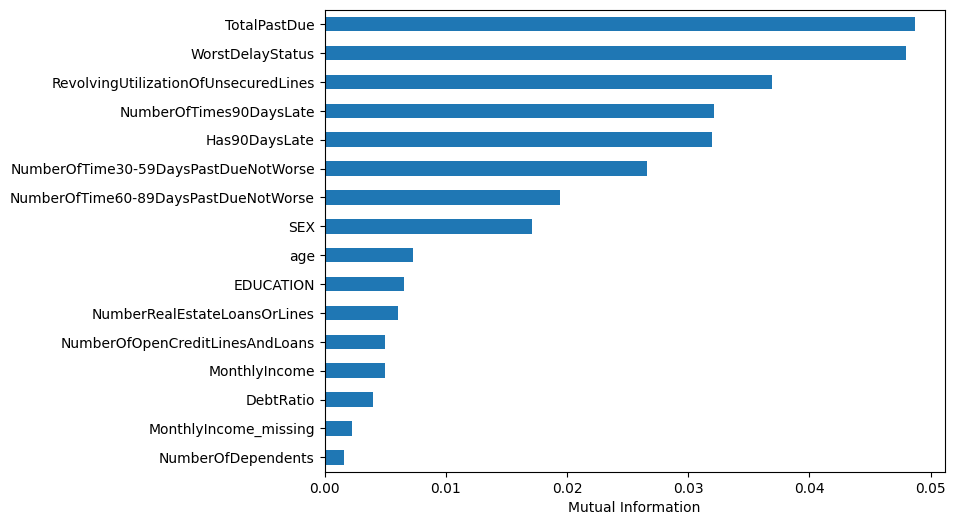

In [54]:
X = train_df.drop(columns=[target, "Is_Outlier"])
y = train_df[target]

mi = mutual_info_classif(X, y, random_state=42)

mi_scores = pd.Series(mi, index=X.columns).sort_values(ascending=False)

print(mi_scores)

mi_scores.sort_values().plot.barh(figsize=(8, 6))
plt.xlabel("Mutual Information")
plt.show()

## 19. Train data summary

In [55]:
train_numeric_report = train_df.select_dtypes(include=np.number).describe().T

train_numeric_report

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,104797.0,6.173620,216.960110,0.0,0.029924,0.153382,0.555344,22198.0
age,104797.0,52.341508,14.739044,21.0,41.000000,52.000000,63.000000,99.0
SEX,104797.0,0.601057,0.489683,0.0,0.000000,1.000000,1.000000,1.0
EDUCATION,104797.0,2.200282,0.873039,1.0,1.000000,2.000000,3.000000,4.0
NumberOfTime30-59DaysPastDueNotWorse,104797.0,0.244702,0.695424,0.0,0.000000,0.000000,0.000000,13.0
DebtRatio,104797.0,349.161128,1515.546006,0.0,0.175977,0.366682,0.864820,220516.0
MonthlyIncome,104797.0,6394.189004,10178.917654,0.0,3923.000000,5416.000000,7420.000000,1794060.0
NumberOfOpenCreditLinesAndLoans,104797.0,8.465777,5.129409,0.0,5.000000,8.000000,11.000000,57.0
NumberOfTimes90DaysLate,104797.0,0.090814,0.485827,0.0,0.000000,0.000000,0.000000,15.0
NumberRealEstateLoansOrLines,104797.0,1.019380,1.120560,0.0,0.000000,1.000000,2.000000,32.0


In [56]:
new_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate",
]

train_df[new_features].head()

,WorstDelayStatus,TotalPastDue,Has90DaysLate
134668,0,0,0
119703,0,0,0
37115,0,0,0
141624,0,0,0
139483,0,0,0


In [57]:
new_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate",
]

train_df.groupby(target)[new_features].mean().T

SeriousDlqin,0,1
WorstDelayStatus,0.258618,1.487346
TotalPastDue,0.283852,2.051916
Has90DaysLate,0.033540,0.342589


## 20. Test data summary


In [58]:
test_numeric_report = test_df.select_dtypes(include=np.number).describe().T

test_numeric_report

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,44913.0,4.660321,203.115815,0.0,0.029542,0.153936,0.556688,29110.0
age,44913.0,52.281077,14.767130,21.0,41.000000,52.000000,63.000000,99.0
SEX,44913.0,0.602031,0.489485,0.0,0.000000,1.000000,1.000000,1.0
EDUCATION,44913.0,2.198384,0.872026,1.0,1.000000,2.000000,3.000000,4.0
NumberOfTime30-59DaysPastDueNotWorse,44913.0,0.248347,0.703317,0.0,0.000000,0.000000,0.000000,9.0
DebtRatio,44913.0,342.658266,1277.865620,0.0,0.176137,0.368217,0.883749,110952.0
MonthlyIncome,44913.0,6434.311313,10600.336519,0.0,3900.000000,5416.000000,7300.000000,1072500.0
NumberOfOpenCreditLinesAndLoans,44913.0,8.472224,5.153499,0.0,5.000000,8.000000,11.000000,57.0
NumberOfTimes90DaysLate,44913.0,0.089618,0.484859,0.0,0.000000,0.000000,0.000000,17.0
NumberRealEstateLoansOrLines,44913.0,1.020551,1.124151,0.0,0.000000,1.000000,2.000000,25.0


In [59]:
new_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate",
]

test_df[new_features].head()

,WorstDelayStatus,TotalPastDue,Has90DaysLate
76820,0,0,0
135401,0,0,0
5324,2,1,0
90486,0,0,0
43461,0,0,0


In [60]:
summary_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate"
]

test_df.groupby(target)[summary_features].mean().T

SeriousDlqin,0,1
WorstDelayStatus,0.267747,1.419507
TotalPastDue,0.291180,1.977050
Has90DaysLate,0.034803,0.322646


***

assignment -- Aryan Hashemi

***

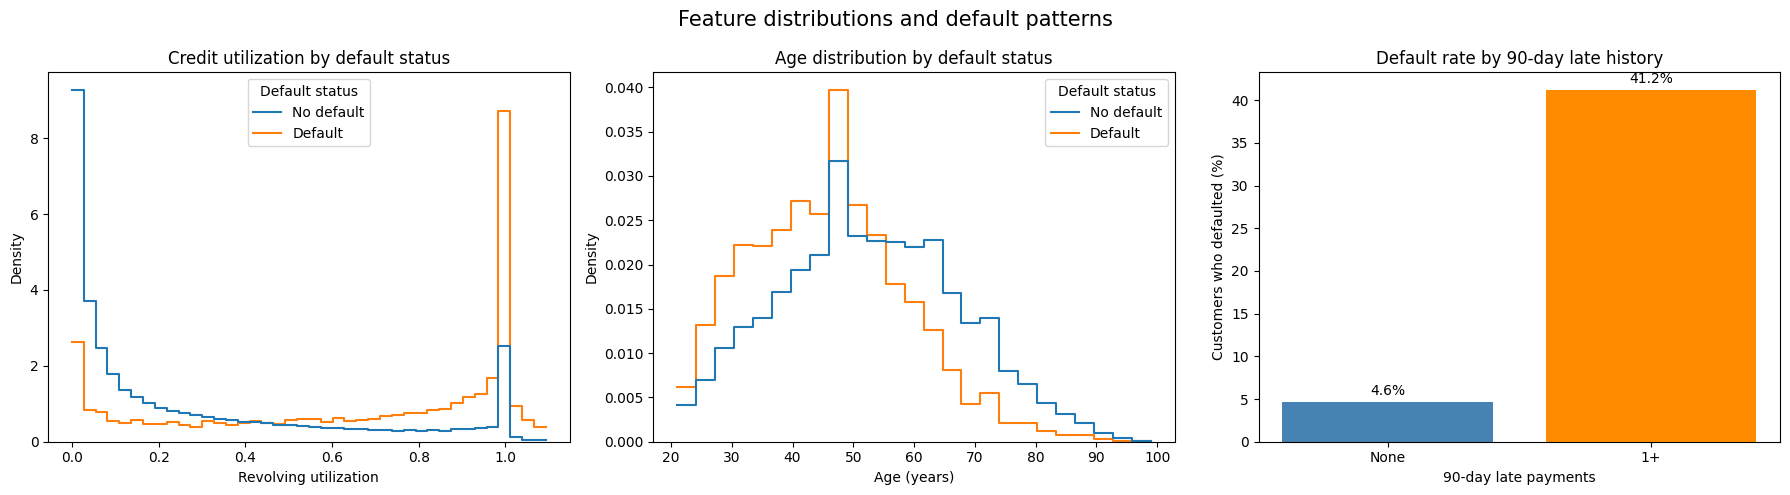

In [63]:
from IPython.display import display, HTML
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# حذف ستون نشت هدف و ردیف‌هایی که سن نامعتبر دارند
feature_df = data.drop(columns=["NumberOfDefault"]).copy()
feature_df = feature_df[feature_df["age"].between(18, 100)].copy()

target = "SeriousDlqin"
util_col = "RevolvingUtilizationOfUnsecuredLines"
late_col = "NumberOfTimes90DaysLate"

# برچسب‌های انگلیسی برای استفاده در راهنمای پلات‌ها
feature_df["Default status"] = feature_df[target].map({
    0: "No default",
    1: "Default"
})

# محاسبهٔ آمار موردنیاز
overall_rate = feature_df[target].mean() * 100

util_median = feature_df.groupby(target)[util_col].median()
util_p99 = feature_df[util_col].quantile(0.99)
util_max = feature_df[util_col].max()

feature_df["Late group"] = np.where(
    feature_df[late_col] == 0,
    "No late payments",
    "One or more late payments"
)

late_rate = feature_df.groupby("Late group")[target].mean() * 100
zero_late_percent = (feature_df[late_col] == 0).mean() * 100

feature_df["Age group"] = pd.cut(
    feature_df["age"],
    bins=[17, 29, 39, 49, 59, 69, 100],
    labels=["18 to 29", "30 to 39", "40 to 49",
            "50 to 59", "60 to 69", "70+"]
)

age_rate = (
    feature_df.groupby("Age group", observed=False)[target].mean() * 100
)

income_missing = feature_df["MonthlyIncome"].isna().mean() * 100

# نمایش متن فارسی راست‌چین، با قرار دادن اعداد در خط جداگانه
display(HTML(f"""
<div dir="rtl" style="
    direction: rtl;
    text-align: right;
    font-family: sans-serif;
    line-height: 1.9;
    padding: 12px;
">
    <h2>بررسی توزیع ویژگی‌ها و الگوهای مرتبط با نکول</h2>

    <p>
    برای این بررسی، ستون <b>NumberOfDefault</b> را کنار گذاشتم، چون در بخش قبلی
    به‌عنوان نشت هدف شناسایی شده بود. همچنین ردیف‌هایی را که سن کمتر از ۱۸ یا
    بیشتر از ۱۰۰ سال داشتند از تحلیل خارج کردم. این تحلیل اکتشافی است و به‌تنهایی
    علت نکول را مشخص نمی‌کند.
    </p>

    <p><b>نرخ کلی نکول در داده:</b><br>
    <span dir="ltr" style="display:inline-block; text-align:left;">
    {overall_rate:.1f}%
    </span></p>

    <p>
    <b>استفاده از اعتبار:</b> توزیع این ویژگی راست‌چوله است و چند مقدار بسیار بزرگ
    دارد. برای مقایسهٔ دو گروه، میانهٔ میزان استفاده از اعتبار را بررسی کردم.
    نمودار فقط تا صدک ۹۹ را نشان می‌دهد تا مقدارهای بسیار بزرگ، شکل بقیهٔ داده‌ها
    را فشرده نکنند؛ خود داده تغییر نکرده است.
    </p>

    <p><b>میانه در گروه نکول‌کرده:</b><br>
    <span dir="ltr" style="display:inline-block; text-align:left;">
    {util_median.loc[1]:.3f}
    </span></p>

    <p><b>میانه در گروه بدون نکول:</b><br>
    <span dir="ltr" style="display:inline-block; text-align:left;">
    {util_median.loc[0]:.3f}
    </span></p>

    <p><b>صدک ۹۹ استفاده از اعتبار و بیشترین مقدار ثبت‌شده:</b><br>
    <span dir="ltr" style="display:inline-block; text-align:left;">
    {util_p99:.2f} &nbsp; | &nbsp; {util_max:,.0f}
    </span></p>

    <p>
    <b>تأخیر ۹۰روزه:</b> بیشتر مشتری‌ها در این ویژگی مقدار صفر دارند. با این حال،
    نرخ نکول در گروهی که دست‌کم یک تأخیر ۹۰روزه داشته‌اند، بیشتر است.
    </p>

    <p><b>درصد مشتریان بدون تأخیر ۹۰روزه:</b><br>
    <span dir="ltr" style="display:inline-block; text-align:left;">
    {zero_late_percent:.1f}%
    </span></p>

    <p><b>نرخ نکول در گروه بدون تأخیر:</b><br>
    <span dir="ltr" style="display:inline-block; text-align:left;">
    {late_rate.loc["No late payments"]:.1f}%
    </span></p>

    <p><b>نرخ نکول در گروه دارای حداقل یک تأخیر:</b><br>
    <span dir="ltr" style="display:inline-block; text-align:left;">
    {late_rate.loc["One or more late payments"]:.1f}%
    </span></p>

    <p>
    <b>سن:</b> نرخ نکول در گروه‌های سنی پایین‌تر بیشتر از گروه‌های سنی بالاتر است.
    این تفاوت یک الگوی مشاهده‌شده در داده است و رابطهٔ علت و معلولی را ثابت نمی‌کند.
    </p>

    <p><b>نرخ نکول در سن ۱۸ تا ۲۹ سال:</b><br>
    <span dir="ltr" style="display:inline-block; text-align:left;">
    {age_rate.loc["18 to 29"]:.1f}%
    </span></p>

    <p><b>نرخ نکول در سن ۷۰ سال به بالا:</b><br>
    <span dir="ltr" style="display:inline-block; text-align:left;">
    {age_rate.loc["70+"]:.1f}%
    </span></p>

    <p>
    <b>نکتهٔ کیفیت داده:</b> حدود یک‌پنجم مقدارهای درآمد ماهانه خالی است.
    پیش از استفاده از این ستون در تحلیل بعدی، باید برای مقدارهای گمشده تصمیم گرفت.
    </p>

    <p><b>درصد مقدارهای گمشدهٔ درآمد ماهانه:</b><br>
    <span dir="ltr" style="display:inline-block; text-align:left;">
    {income_missing:.1f}%
    </span></p>

    <h3>سه ویژگی برای شروع تحلیل ریسک</h3>
    <p>
    برای شروع، سابقهٔ تأخیر ۹۰روزه، میزان استفاده از اعتبار گردشی، و سن را انتخاب
    می‌کنم. هر سه در این داده تفاوت‌هایی میان گروه‌های نکول‌کرده و بدون نکول نشان
    می‌دهند؛ برای نتیجه‌گیری قطعی باید عوامل دیگر هم بررسی شوند.
    </p>
</div>
"""))

# داده‌های نمودارها
util_plot = feature_df[feature_df[util_col] <= util_p99]
late_plot_rate = late_rate.reindex([
    "No late payments",
    "One or more late payments"
])

# ساخت سه نمودار
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# توزیع استفاده از اعتبار بر اساس وضعیت نکول
sns.histplot(
    data=util_plot,
    x=util_col,
    hue="Default status",
    hue_order=["No default", "Default"],
    stat="density",
    common_norm=False,
    bins=40,
    element="step",
    fill=False,
    ax=axes[0]
)
axes[0].set_title("Credit utilization by default status")
axes[0].set_xlabel("Revolving utilization")
axes[0].set_ylabel("Density")

# توزیع سن بر اساس وضعیت نکول
sns.histplot(
    data=feature_df,
    x="age",
    hue="Default status",
    hue_order=["No default", "Default"],
    stat="density",
    common_norm=False,
    bins=25,
    element="step",
    fill=False,
    ax=axes[1]
)
axes[1].set_title("Age distribution by default status")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Density")

# نرخ نکول بر اساس سابقهٔ تأخیر ۹۰روزه
bars = axes[2].bar(
    ["None", "1+"],
    late_plot_rate.values,
    color=["steelblue", "darkorange"]
)
axes[2].bar_label(bars, fmt="%.1f%%", padding=3)
axes[2].set_title("Default rate by 90-day late history")
axes[2].set_xlabel("90-day late payments")
axes[2].set_ylabel("Customers who defaulted (%)")

fig.suptitle("Feature distributions and default patterns", fontsize=15)
plt.tight_layout()
plt.show()